# Predicting Customer Churn in Wireless Telecommunications Using Machine Learning

## IT5022 - Fundamentals of Machine Learning - Assignment - MS26935140 | MS26923260

### Problem Statement
Customer churn is an important challenge for wireless telecommunications service providers because customers who discontinue their service can reduce recurring revenue and increase customer acquisition requirements. Identifying customers who are at elevated risk of leaving before churn occurs can support more targeted customer-retention strategies. This project investigates whether historical customer account characteristics, service-usage behaviour, billing information, equipment information, service interactions, and demographic characteristics can be used to predict whether a customer is likely to churn in a future period using supervised machine-learning techniques.



*   **Machine Learning Approach :** Supervised Learning – Binary Classification
*   **Dataset :** Cell2Cell telecom churn
*   **Target :** `Churn` (`Yes` = churn, `No` = non-churn)
*   **Development Platform :** Jupyter Notebook
*   **Programming Language :** Python

## 0. Imports, Environment and reproducibility

In [34]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Setting random seed for Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings - columns -> no limit | rows -> upto 200
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

print("Environment is Ready")

Environment is Ready


## 1. Load the labelled training data and unlabeled holdout data

In [35]:
# Assume dataset files are in the data folder

# Change the DATA_DIR only if files are in a different folder
DATA_DIR = Path("../data")

train_path = DATA_DIR / "cell2celltrain.csv"
holdout_path = DATA_DIR / "cell2cellholdout.csv"

# Check that both required files are exists
missing_files = [
    path for path in [train_path, holdout_path]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required dataset file(s) were not found \n"
        + "\n". join(str(path) for path in missing_files)
    )

# Load datasets
train_raw = pd.read_csv(train_path)
holdout_raw = pd.read_csv(holdout_path)

## 2. Dataset integrity audit

The purpose of Data Integrity Audit is to **inspect and diagnose the raw data only**. No imputation, encoding, scaling, outlier removal, feature engineering, feature selection, class-imbalance treatment, or model fitting is performed here.

The audit focuses on understanding the dataset structure and identifying data-quality or representation issues that may need to be addressed in later stages.

### 2.1 Dataset Source and Context

This project uses the publicly available **Cell2Cell telecommunications customer churn dataset**. The dataset contains customer-level information relevant to churn analysis, including service usage, billing, account characteristics, equipment information, customer-care interactions, credit-related information, household/demographic characteristics, and retention-related information.

Two source files are used in this project:

- `cell2celltrain.csv` contains customer records with observed churn outcomes and is therefore treated as the **labelled dataset**.
- `cell2cellholdout.csv` contains additional customer records but its `Churn` values are missing. It is therefore treated as an **unlabelled holdout dataset** and cannot be used to calculate model-performance metrics.

### 2.2 Dataset Shape and Structure

In [36]:
# Dataset dimensions
print("Labelled dataset shape:", train_raw.shape)
print("Holdout dataset shape:", holdout_raw.shape)

# Verify schema
print("\nNumber of columns in labelled data:", train_raw.shape[1])
print("Number of columns in holdout data:", holdout_raw.shape[1])
print(
    "Same column names and order:",
    train_raw.columns.tolist() == holdout_raw.columns.tolist()
)

Labelled dataset shape: (51047, 58)
Holdout dataset shape: (20000, 58)

Number of columns in labelled data: 58
Number of columns in holdout data: 58
Same column names and order: True


**Interpretation**

The labelled dataset contains **51,047 customer observations and 58 variables**, while the holdout dataset contains **20,000 observations and the same 58-column schema**. This confirms that the two files are structurally compatible. The labelled data will later support model development and evaluation, while the unlabelled holdout data can only be used for final inference because its true churn outcomes are unavailable.

### 2.3 Feature and Target Overview

In [37]:
# Preview both datasets
display(train_raw.head())
display(holdout_raw.head())

# Basic feature/target overview
print("\nNumber of variables:", train_raw.shape[1])
print("Target variable: Churn")
print("Target values:", train_raw["Churn"].dropna().unique())
print("\nUnique CustomerID values:", train_raw["CustomerID"].nunique())

# Display all column names
train_raw.columns.tolist()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,0.7,6.3,0.0,0.0,97.2,0.0,0.0,58.0,24.0,1.3,0.0,0.3,61,2,1,SEAPOR503,2.0,2.0,361.0,62.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,Yes,Yes,1,0,No,No,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,0.0,2.7,0.0,0.0,0.0,0.0,0.0,5.0,1.0,0.3,0.0,0.0,58,1,1,PITHOM412,2.0,1.0,1504.0,40.0,42.0,Yes,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,Yes,No,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.3,0.0,1.3,3.7,0.0,0.0,0.0,60,1,1,MILMIL414,1.0,1.0,1812.0,26.0,26.0,Yes,No,No,No,No,Unknown,No,No,No,No,No,Yes,0,0,Yes,No,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,7.7,76.0,4.3,1.3,200.3,370.3,147.0,555.7,303.7,59.7,0.0,22.7,59,2,2,PITHOM412,9.0,4.0,458.0,30.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,Yes,No,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53,2,2,OKCTUL918,4.0,3.0,852.0,46.0,54.0,No,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,No,Yes,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000006,NaN,57.49,483.0,37.0,0.25,23.0,0.0,532.0,51.0,8.3,1.0,61.3,1.7,0.3,55.3,46.3,6.3,83.7,157.0,9.3,0.0,5.7,56,1,1,MILMIL414,7,6,240,30.0,0.0,No,No,Yes,Yes,Yes,Unknown,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,5,No,1,150,No,5-Low,Other,Other,No
1,3000018,NaN,55.23,570.0,72.0,0.00,0.0,0.0,38.0,0.0,9.7,0.7,77.0,8.7,0.0,106.3,14.7,0.7,97.3,90.3,10.3,0.0,0.0,57,1,1,NNYSYR315,6,4,434,56.0,0.0,No,No,Yes,No,No,Known,No,No,No,No,Yes,Yes,0,0,Yes,No,0,6,No,2,80,No,1-Highest,Other,Professional,No
2,3000034,NaN,97.34,1039.0,50.0,4.95,420.0,0.0,198.0,23.3,12.7,3.0,176.0,11.3,0.3,213.9,103.3,0.3,238.3,192.3,15.7,0.0,4.0,55,1,1,MILMIL414,3,3,700,38.0,24.0,No,No,No,No,No,Unknown,No,No,No,No,No,No,0,0,Yes,No,0,4,No,3,10,No,3-Good,Suburban,Crafts,Yes
3,3000070,NaN,35.59,153.0,30.0,0.00,16.0,0.0,30.0,7.3,2.0,0.7,17.3,0.0,0.0,33.1,8.0,4.7,48.3,7.0,2.7,0.0,0.3,59,3,2,SLCSLC801,6,5,48,46.0,0.0,Yes,No,Yes,Yes,Yes,Known,Yes,Yes,Yes,No,No,Yes,0,0,No,Yes,0,4,No,1,200,No,1-Highest,Other,Other,No
4,3000074,NaN,55.27,1213.0,50.0,0.74,0.0,1.3,169.0,1.0,2.7,6.0,43.7,4.3,0.0,490.1,50.7,8.3,189.3,105.0,8.7,0.0,4.3,52,1,1,OKCTUL918,4,4,408,58.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,3,No,0,10,No,1-Highest,Suburban,Other,No



Number of variables: 58
Target variable: Churn
Target values: ['Yes' 'No']

Unique CustomerID values: 51047


['CustomerID',
 'Churn',
 'MonthlyRevenue',
 'MonthlyMinutes',
 'TotalRecurringCharge',
 'DirectorAssistedCalls',
 'OverageMinutes',
 'RoamingCalls',
 'PercChangeMinutes',
 'PercChangeRevenues',
 'DroppedCalls',
 'BlockedCalls',
 'UnansweredCalls',
 'CustomerCareCalls',
 'ThreewayCalls',
 'ReceivedCalls',
 'OutboundCalls',
 'InboundCalls',
 'PeakCallsInOut',
 'OffPeakCallsInOut',
 'DroppedBlockedCalls',
 'CallForwardingCalls',
 'CallWaitingCalls',
 'MonthsInService',
 'UniqueSubs',
 'ActiveSubs',
 'ServiceArea',
 'Handsets',
 'HandsetModels',
 'CurrentEquipmentDays',
 'AgeHH1',
 'AgeHH2',
 'ChildrenInHH',
 'HandsetRefurbished',
 'HandsetWebCapable',
 'TruckOwner',
 'RVOwner',
 'Homeownership',
 'BuysViaMailOrder',
 'RespondsToMailOffers',
 'OptOutMailings',
 'NonUSTravel',
 'OwnsComputer',
 'HasCreditCard',
 'RetentionCalls',
 'RetentionOffersAccepted',
 'NewCellphoneUser',
 'NotNewCellphoneUser',
 'ReferralsMadeBySubscriber',
 'IncomeGroup',
 'OwnsMotorcycle',
 'AdjustmentsToCreditRat

### 2.4 Data-Type and Semantic-Type Audit

In [38]:
# General dataframe information
train_raw.info()

# Data-type/cardinality summary
dtype_summary = pd.DataFrame({
    "Pandas_Type": train_raw.dtypes.astype(str),
    "Unique_Values": train_raw.nunique(dropna=True)
})

display(dtype_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls          51047 non-null  flo

,Pandas_Type,Unique_Values
CustomerID,int64,51047
Churn,object,2
MonthlyRevenue,float64,12665
MonthlyMinutes,float64,2719
TotalRecurringCharge,float64,214
DirectorAssistedCalls,float64,146
OverageMinutes,float64,746
RoamingCalls,float64,530
PercChangeMinutes,float64,2262
PercChangeRevenues,float64,2899


**Semantic feature dictionary (58 variables)**

The following table documents the meaning and semantic type of every raw variable, separately from its pandas storage type. Descriptions are based on the column names and observed values.

In [39]:
feature_descriptions = [
    ('CustomerID', 'Identifier', 'Unique customer record identifier', 'Identifier'),
    ('Churn', 'Target', 'Observed customer churn outcome (Yes/No)', 'Binary target'),
    ('MonthlyRevenue', 'Billing', 'Recorded monthly customer revenue', 'Numerical measure'),
    ('MonthlyMinutes', 'Usage', 'Recorded monthly call minutes', 'Numerical measure'),
    ('TotalRecurringCharge', 'Billing', 'Total recurring account charge', 'Numerical measure'),
    ('DirectorAssistedCalls', 'Usage', 'Recorded directory-assisted call activity', 'Numerical measure'),
    ('OverageMinutes', 'Usage', 'Recorded minutes exceeding a plan allowance', 'Numerical measure'),
    ('RoamingCalls', 'Usage', 'Recorded roaming-call activity', 'Numerical measure'),
    ('PercChangeMinutes', 'Usage', 'Recorded change measure for minutes; exact unit not verified', 'Numerical measure'),
    ('PercChangeRevenues', 'Billing', 'Recorded change measure for revenue; exact unit not verified', 'Numerical measure'),
    ('DroppedCalls', 'Call quality', 'Recorded dropped-call activity', 'Numerical measure'),
    ('BlockedCalls', 'Call quality', 'Recorded blocked-call activity', 'Numerical measure'),
    ('UnansweredCalls', 'Usage', 'Recorded unanswered-call activity', 'Numerical measure'),
    ('CustomerCareCalls', 'Service', 'Recorded customer-care call activity', 'Numerical measure'),
    ('ThreewayCalls', 'Usage', 'Recorded three-way call activity', 'Numerical measure'),
    ('ReceivedCalls', 'Usage', 'Recorded received-call activity', 'Numerical measure'),
    ('OutboundCalls', 'Usage', 'Recorded outbound-call activity', 'Numerical measure'),
    ('InboundCalls', 'Usage', 'Recorded inbound-call activity', 'Numerical measure'),
    ('PeakCallsInOut', 'Usage', 'Recorded peak-period inbound/outbound call activity', 'Numerical measure'),
    ('OffPeakCallsInOut', 'Usage', 'Recorded off-peak inbound/outbound call activity', 'Numerical measure'),
    ('DroppedBlockedCalls', 'Call quality', 'Recorded combined dropped/blocked call activity', 'Numerical measure'),
    ('CallForwardingCalls', 'Usage', 'Recorded call-forwarding activity', 'Numerical measure'),
    ('CallWaitingCalls', 'Usage', 'Recorded call-waiting activity', 'Numerical measure'),
    ('MonthsInService', 'Tenure', 'Recorded months of customer service', 'Numerical count'),
    ('UniqueSubs', 'Subscriptions', 'Number of unique subscriptions', 'Numerical count'),
    ('ActiveSubs', 'Subscriptions', 'Number of active subscriptions', 'Numerical count'),
    ('ServiceArea', 'Geography', 'Coded customer service area', 'Nominal categorical'),
    ('Handsets', 'Equipment', 'Recorded number of handsets', 'Numerical count'),
    ('HandsetModels', 'Equipment', 'Recorded number of handset models', 'Numerical count'),
    ('CurrentEquipmentDays', 'Equipment', 'Recorded days associated with current equipment', 'Numerical measure'),
    ('AgeHH1', 'Household', 'Recorded age for household member 1; zero coding unverified', 'Numerical measure'),
    ('AgeHH2', 'Household', 'Recorded age for household member 2; zero coding unverified', 'Numerical measure'),
    ('ChildrenInHH', 'Household', 'Indicator for children in household', 'Binary categorical'),
    ('HandsetRefurbished', 'Equipment', 'Indicator for refurbished handset', 'Binary categorical'),
    ('HandsetWebCapable', 'Equipment', 'Indicator for web-capable handset', 'Binary categorical'),
    ('TruckOwner', 'Household', 'Indicator for truck ownership', 'Binary categorical'),
    ('RVOwner', 'Household', 'Indicator for recreational-vehicle ownership', 'Binary categorical'),
    ('Homeownership', 'Household', 'Whether homeownership information is Known/Unknown; not a Yes/No ownership flag', 'Nominal categorical'),
    ('BuysViaMailOrder', 'Marketing', 'Indicator for mail-order purchasing', 'Binary categorical'),
    ('RespondsToMailOffers', 'Marketing', 'Indicator for responding to mail offers', 'Binary categorical'),
    ('OptOutMailings', 'Marketing', 'Indicator for opting out of mailings', 'Binary categorical'),
    ('NonUSTravel', 'Household', 'Indicator for non-US travel', 'Binary categorical'),
    ('OwnsComputer', 'Household', 'Indicator for computer ownership', 'Binary categorical'),
    ('HasCreditCard', 'Household', 'Indicator for credit-card possession', 'Binary categorical'),
    ('RetentionCalls', 'Retention', 'Recorded count of retention-related calls', 'Numerical count'),
    ('RetentionOffersAccepted', 'Retention', 'Recorded count of accepted retention offers', 'Numerical count'),
    ('NewCellphoneUser', 'Customer profile', 'Indicator for new cellphone user', 'Binary categorical'),
    ('NotNewCellphoneUser', 'Customer profile', 'Indicator for not-new cellphone user', 'Binary categorical'),
    ('ReferralsMadeBySubscriber', 'Customer profile', 'Recorded count of referrals made by subscriber', 'Numerical count'),
    ('IncomeGroup', 'Household', 'Coded income group; exact mapping and ordering not verified', 'Coded categorical'),
    ('OwnsMotorcycle', 'Household', 'Indicator for motorcycle ownership', 'Binary categorical'),
    ('AdjustmentsToCreditRating', 'Credit', 'Recorded count/code of credit-rating adjustments; exact meaning unverified', 'Numerical code/count'),
    ('HandsetPrice', 'Equipment', 'Recorded handset price or explicit Unknown value', 'Numerical-like, stored as text'),
    ('MadeCallToRetentionTeam', 'Retention', 'Indicator for contact with retention team', 'Binary categorical'),
    ('CreditRating', 'Credit', 'Ordered credit rating labels from Highest to Lowest', 'Ordinal categorical'),
    ('PrizmCode', 'Demographics', 'Categorical area/demographic segment code', 'Nominal categorical'),
    ('Occupation', 'Demographics', 'Recorded occupation category', 'Nominal categorical'),
    ('MaritalStatus', 'Household', 'Recorded marital-status response (Yes/No/Unknown)', 'Nominal categorical'),

]

feature_dictionary = pd.DataFrame(
    feature_descriptions,
    columns=["Feature", "Domain", "Meaning", "Semantic_Type"]
)
feature_dictionary["Pandas_Type"] = feature_dictionary["Feature"].map(
    train_raw.dtypes.astype(str).to_dict()
)

# Verify that all original columns are documented exactly once.
assert len(feature_dictionary) == train_raw.shape[1]
assert set(feature_dictionary["Feature"]) == set(train_raw.columns)

display(feature_dictionary)

,Feature,Domain,Meaning,Semantic_Type,Pandas_Type
0,CustomerID,Identifier,Unique customer record identifier,Identifier,int64
1,Churn,Target,Observed customer churn outcome (Yes/No),Binary target,object
2,MonthlyRevenue,Billing,Recorded monthly customer revenue,Numerical measure,float64
3,MonthlyMinutes,Usage,Recorded monthly call minutes,Numerical measure,float64
4,TotalRecurringCharge,Billing,Total recurring account charge,Numerical measure,float64
5,DirectorAssistedCalls,Usage,Recorded directory-assisted call activity,Numerical measure,float64
6,OverageMinutes,Usage,Recorded minutes exceeding a plan allowance,Numerical measure,float64
7,RoamingCalls,Usage,Recorded roaming-call activity,Numerical measure,float64
8,PercChangeMinutes,Usage,Recorded change measure for minutes; exact uni...,Numerical measure,float64
9,PercChangeRevenues,Billing,Recorded change measure for revenue; exact uni...,Numerical measure,float64


### 2.5 Missing-Value and Missing-Representation

Missing information can appear as actual null values (`NaN`) or as explicit text representations such as `Unknown`. These forms are audited separately because they should not automatically be assumed to have the same meaning.

In [40]:
# Complete audit table
audit_table = pd.DataFrame({
    "Data_Type": train_raw.dtypes.astype(str),
    "Missing_Count": train_raw.isna().sum(),
    "Missing_Percentage": (train_raw.isna().mean() * 100).round(2),
    "Unique_Values": train_raw.nunique(dropna=True)
})

audit_table = audit_table.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(audit_table)

# Show only columns containing actual null values
missing_summary = audit_table[
    audit_table["Missing_Count"] > 0
][["Missing_Count", "Missing_Percentage"]]

display(missing_summary)

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
AgeHH2,float64,909,1.78,43
AgeHH1,float64,909,1.78,43
PercChangeMinutes,float64,367,0.72,2262
PercChangeRevenues,float64,367,0.72,2899
MonthlyRevenue,float64,156,0.31,12665
MonthlyMinutes,float64,156,0.31,2719
TotalRecurringCharge,float64,156,0.31,214
DirectorAssistedCalls,float64,156,0.31,146
OverageMinutes,float64,156,0.31,746
RoamingCalls,float64,156,0.31,530


,Missing_Count,Missing_Percentage
AgeHH2,909,1.78
AgeHH1,909,1.78
PercChangeMinutes,367,0.72
PercChangeRevenues,367,0.72
MonthlyRevenue,156,0.31
MonthlyMinutes,156,0.31
TotalRecurringCharge,156,0.31
DirectorAssistedCalls,156,0.31
OverageMinutes,156,0.31
RoamingCalls,156,0.31


In [41]:
# Audit explicit 'Unknown' representations in text columns
unknown_summary = []

for col in train_raw.select_dtypes(include="object").columns:
    unknown_count = (
        train_raw[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

    if unknown_count > 0:
        unknown_summary.append({
            "Feature": col,
            "Unknown_Count": int(unknown_count),
            "Unknown_Percentage": round(
                unknown_count / len(train_raw) * 100, 2
            )
        })

unknown_summary = pd.DataFrame(unknown_summary)
display(unknown_summary)

,Feature,Unknown_Count,Unknown_Percentage
0,Homeownership,17060,33.42
1,HandsetPrice,28982,56.78
2,MaritalStatus,19700,38.59


**Interpretation**

The raw dataset contains actual null values in multiple variables. In addition, explicit `Unknown` values occur in `Homeownership`, `HandsetPrice`, and `MaritalStatus`. These representations are recorded rather than modified during the audit.

The distinction is important because an explicit `Unknown` category may carry a different meaning from an actual missing value. The appropriate treatment of each case will be decided later during preprocessing.


### 2.6 Duplicate and Identifier Integrity

In [42]:
# Duplicate analysis
duplicate_rows = train_raw.duplicated().sum()
duplicate_customer_ids = train_raw["CustomerID"].duplicated().sum()

print("Complete duplicate rows:", duplicate_rows)
print("Duplicate CustomerID values:", duplicate_customer_ids)
print("Number of rows:", len(train_raw))
print("Unique CustomerID values:", train_raw["CustomerID"].nunique())

Complete duplicate rows: 0
Duplicate CustomerID values: 0
Number of rows: 51047
Unique CustomerID values: 51047


**Cross-file identifier overlap**

Check whether the same `CustomerID` occurs in both source files.

In [43]:
# Check for overlapping customer identifiers across the two raw files.
overlapping_ids = set(train_raw["CustomerID"]) & set(holdout_raw["CustomerID"])
print("Overlapping CustomerIDs between labelled and holdout:", len(overlapping_ids))

Overlapping CustomerIDs between labelled and holdout: 0


**Interpretation**

No complete duplicate records are present in the labelled dataset, and every `CustomerID` is unique. Therefore, the raw data shows no evidence of exact duplicated customer observations. `CustomerID` is confirmed to behave as a record identifier.

The labelled and holdout files also contain **no overlapping customer identifiers**, indicating that the supplied source files contain distinct customer IDs.

### 2.7 Categorical Cardinality and Consistency

Categorical variables are inspected for:

- the number of distinct categories;
- high-cardinality variables;
- explicit missing/unknown categories;
- obvious differences caused only by capitalisation or surrounding spaces.

This is a diagnostic check only; no categories are encoded, grouped or replaced here.

In [44]:
# Identify object/categorical columns
categorical_cols = train_raw.select_dtypes(
    include="object"
).columns.tolist()

categorical_summary = pd.DataFrame({
    "Feature": categorical_cols,
    "Unique_Values_Including_Missing": [
        train_raw[col].nunique(dropna=False)
        for col in categorical_cols
    ]
}).sort_values(
    "Unique_Values_Including_Missing",
    ascending=False
)

display(categorical_summary)

,Feature,Unique_Values_Including_Missing
1,ServiceArea,748
17,HandsetPrice,16
21,Occupation,8
19,CreditRating,7
20,PrizmCode,4
22,MaritalStatus,3
12,OwnsComputer,2
18,MadeCallToRetentionTeam,2
16,OwnsMotorcycle,2
15,NotNewCellphoneUser,2


In [45]:
# Inspect actual category frequencies
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(train_raw[col].value_counts(dropna=False))


--- Churn ---
Churn
No     36336
Yes    14711
Name: count, dtype: int64

--- ServiceArea ---
ServiceArea
NYCBRO917    1684
HOUHOU281    1510
DALDAL214    1498
NYCMAN917    1182
APCFCH703     783
             ... 
OHIRAV330       1
KCYHES316       1
AIRGEO843       1
AIRNEW803       1
NCRDNN910       1
Name: count, Length: 748, dtype: int64

--- ChildrenInHH ---
ChildrenInHH
No     38679
Yes    12368
Name: count, dtype: int64

--- HandsetRefurbished ---
HandsetRefurbished
No     43956
Yes     7091
Name: count, dtype: int64

--- HandsetWebCapable ---
HandsetWebCapable
Yes    46046
No      5001
Name: count, dtype: int64

--- TruckOwner ---
TruckOwner
No     41524
Yes     9523
Name: count, dtype: int64

--- RVOwner ---
RVOwner
No     46894
Yes     4153
Name: count, dtype: int64

--- Homeownership ---
Homeownership
Known      33987
Unknown    17060
Name: count, dtype: int64

--- BuysViaMailOrder ---
BuysViaMailOrder
No     32596
Yes    18451
Name: count, dtype: int64

--- RespondsToMailOff

In [46]:
# Check for obvious case/whitespace inconsistencies
categorical_consistency = []

for col in categorical_cols:
    original_unique = train_raw[col].dropna().nunique()

    normalized_unique = (
        train_raw[col]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .nunique()
    )

    categorical_consistency.append({
        "Feature": col,
        "Original_Unique": original_unique,
        "Normalized_Unique": normalized_unique,
        "Potential_Case_Whitespace_Inconsistency":
            original_unique != normalized_unique
    })

categorical_consistency = pd.DataFrame(categorical_consistency)
display(categorical_consistency)

,Feature,Original_Unique,Normalized_Unique,Potential_Case_Whitespace_Inconsistency
0,Churn,2,2,False
1,ServiceArea,747,747,False
2,ChildrenInHH,2,2,False
3,HandsetRefurbished,2,2,False
4,HandsetWebCapable,2,2,False
5,TruckOwner,2,2,False
6,RVOwner,2,2,False
7,Homeownership,2,2,False
8,BuysViaMailOrder,2,2,False
9,RespondsToMailOffers,2,2,False


**Interpretation**

The categorical audit shows a mixture of binary, low-cardinality and high-cardinality variables. `ServiceArea` is particularly notable because it contains hundreds of distinct values, whereas many other categorical variables are binary or contain only a small number of categories. The audit also confirms the presence of explicit `Unknown` representations in selected variables.

### 2.8 Numerical Range and Distribution Audit

Numerical variables are inspected using descriptive statistics, percentiles and skewness. This helps identify unusual ranges, highly asymmetric distributions and variables requiring closer investigation.

This section describes the **raw univariate distributions** only. Relationships between predictors and churn are reserved for later exploratory analysis.

In [47]:
# Identify numerical columns
numeric_cols = train_raw.select_dtypes(
    include=np.number
).columns.tolist()

# Detailed numerical summary
numerical_summary = train_raw[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(numerical_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
CustomerID,51047.0,3.201957e+06,116905.561666,3000002.00,3003983.520,3019871.200,3100632.00,3201534.00,3305376.000,3381396.80,3395898.320,3399994.00
MonthlyRevenue,50891.0,5.883449e+01,44.507336,-6.17,10.000,15.475,33.61,48.46,71.065,135.18,225.963,1223.38
MonthlyMinutes,50891.0,5.256534e+02,529.871063,0.00,0.000,20.000,158.00,366.00,723.000,1576.50,2458.300,7359.00
TotalRecurringCharge,50891.0,4.683009e+01,23.848871,-11.00,9.000,10.000,30.00,45.00,60.000,85.00,120.000,400.00
DirectorAssistedCalls,50891.0,8.952290e-01,2.228546,0.00,0.000,0.000,0.00,0.25,0.990,4.21,9.650,159.39
OverageMinutes,50891.0,4.002778e+01,96.588076,0.00,0.000,0.000,0.00,3.00,41.000,190.00,429.100,4321.00
RoamingCalls,50891.0,1.236244e+00,9.818294,0.00,0.000,0.000,0.00,0.00,0.300,5.10,21.500,1112.40
PercChangeMinutes,50680.0,-1.154791e+01,257.514772,-3875.00,-848.000,-380.000,-83.00,-5.00,66.000,345.00,739.210,5192.00
PercChangeRevenues,50680.0,-1.191985e+00,39.574915,-1107.70,-104.521,-47.600,-7.10,-0.30,1.600,46.50,115.063,2483.50
DroppedCalls,51047.0,6.011489e+00,9.043955,0.00,0.000,0.000,0.70,3.00,7.700,22.00,42.300,221.70


In [48]:
# Compact range and distribution summary
distribution_summary = pd.DataFrame({
    "Minimum": train_raw[numeric_cols].min(),
    "Median": train_raw[numeric_cols].median(),
    "Mean": train_raw[numeric_cols].mean(),
    "Maximum": train_raw[numeric_cols].max(),
    "Skewness": train_raw[numeric_cols].skew()
})

display(distribution_summary.sort_values(
    "Skewness",
    ascending=False
))

,Minimum,Median,Mean,Maximum,Skewness
CallForwardingCalls,0.00,0.00,1.227692e-02,81.30,91.634791
UniqueSubs,1.00,1.00,1.532157e+00,196.00,79.635758
RoamingCalls,0.00,0.00,1.236244e+00,1112.40,57.881773
ReferralsMadeBySubscriber,0.00,0.00,5.206966e-02,35.00,36.739725
AdjustmentsToCreditRating,0.00,0.00,5.391110e-02,25.00,18.623149
ThreewayCalls,0.00,0.00,2.988383e-01,66.00,17.553060
CustomerCareCalls,0.00,0.00,1.868999e+00,327.30,14.235913
DirectorAssistedCalls,0.00,0.25,8.952290e-01,159.39,13.567882
CallWaitingCalls,0.00,0.30,1.840504e+00,212.70,11.121429
ActiveSubs,0.00,1.00,1.354340e+00,53.00,10.647697


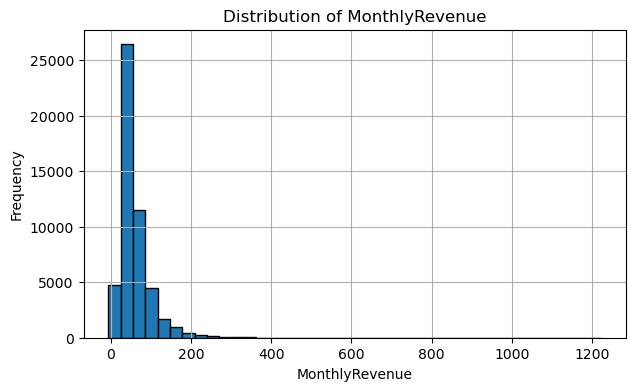

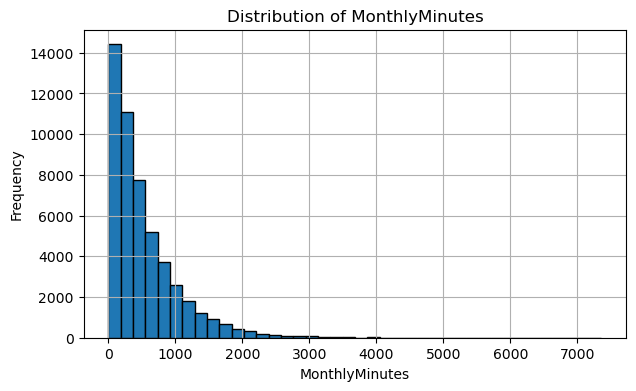

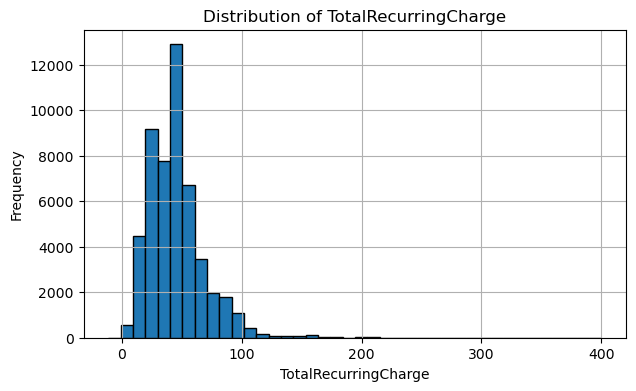

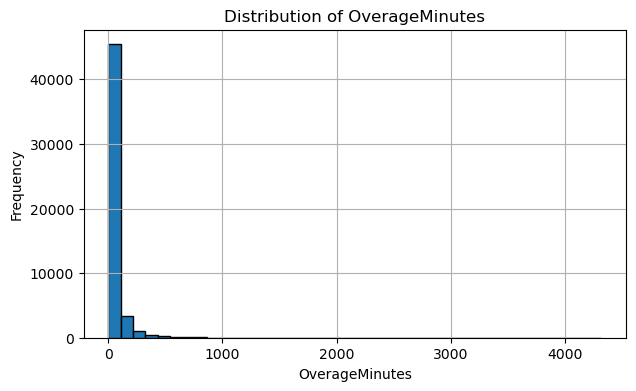

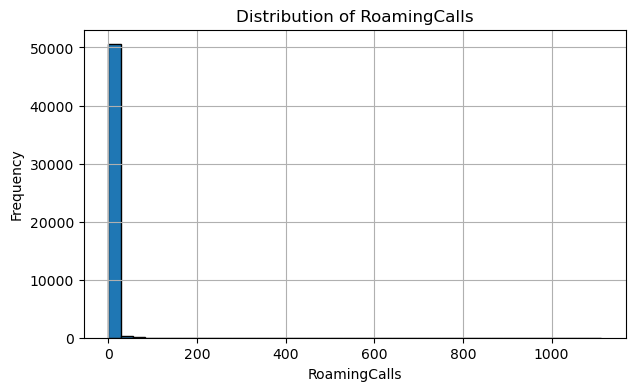

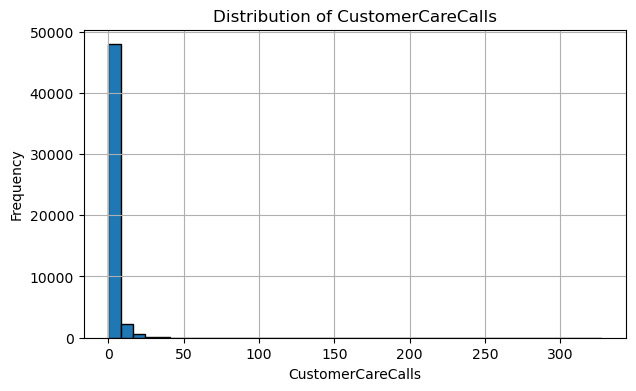

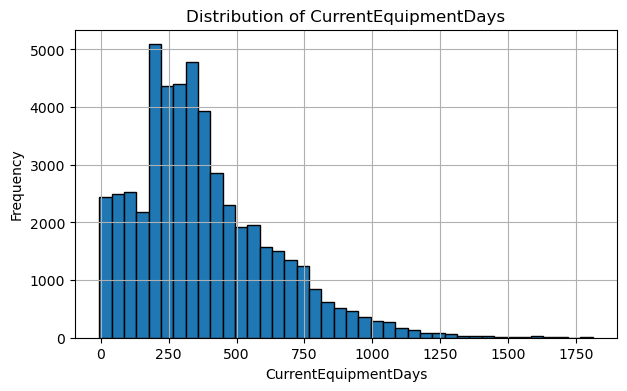

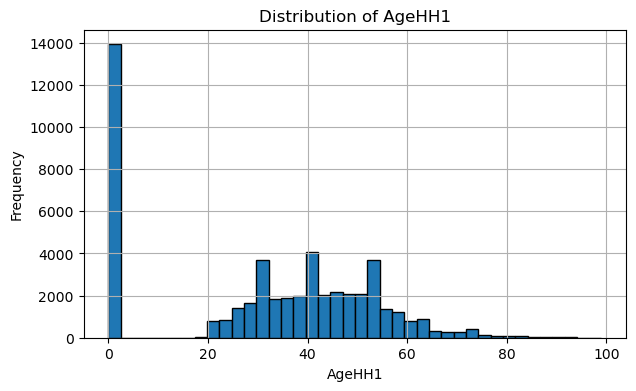

In [49]:
# Representative raw numerical distributions
distribution_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "TotalRecurringCharge",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays",
    "AgeHH1"
]

for col in distribution_features:
    plt.figure(figsize=(7, 4))
    train_raw[col].dropna().hist(
        bins=40,
        edgecolor="black"
    )
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

**Interpretation**

The numerical variables operate on substantially different ranges and several usage-related variables show asymmetric or long-tailed distributions. Large maximum values relative to medians are visible in variables such as call usage and roaming activity. These patterns are recorded as characteristics of the raw data and are investigated further through validity and outlier checks. No scaling or distributional transformation is performed during the audit.

### 2.9 Invalid, Impossible and Suspicious Values

This section checks for values that may be invalid, internally inconsistent or worthy of further investigation. A flagged value is **not automatically treated as an error** because its validity depends on the semantic meaning of the feature.

Negative values and selected logical relationships are inspected without modifying the data.

In [50]:
# Identify numerical variables containing negative values
negative_value_summary = []

for col in numeric_cols:
    negative_count = (train_raw[col] < 0).sum()

    if negative_count > 0:
        negative_value_summary.append({
            "Feature": col,
            "Negative_Count": int(negative_count),
            "Minimum_Value": train_raw[col].min()
        })

negative_value_summary = pd.DataFrame(negative_value_summary)
display(negative_value_summary)

,Feature,Negative_Count,Minimum_Value
0,MonthlyRevenue,3,-6.17
1,TotalRecurringCharge,8,-11.00
2,PercChangeMinutes,26816,-3875.00
3,PercChangeRevenues,28408,-1107.70
4,CurrentEquipmentDays,76,-5.00


In [51]:
# Selected logical consistency checks
logical_checks = pd.Series({
    "ActiveSubs > UniqueSubs":
        (train_raw["ActiveSubs"] > train_raw["UniqueSubs"]).sum(),

    "RetentionOffersAccepted > RetentionCalls":
        (
            train_raw["RetentionOffersAccepted"]
            > train_raw["RetentionCalls"]
        ).sum(),

    "HandsetModels > Handsets":
        (train_raw["HandsetModels"] > train_raw["Handsets"]).sum()
}, name="Violation_Count")

display(logical_checks.to_frame())

# Inspect zero values in household-age fields
print("AgeHH1 zero values:", (train_raw["AgeHH1"] == 0).sum())
print("AgeHH2 zero values:", (train_raw["AgeHH2"] == 0).sum())

,Violation_Count
ActiveSubs > UniqueSubs,0
RetentionOffersAccepted > RetentionCalls,0
HandsetModels > Handsets,0


AgeHH1 zero values: 13917
AgeHH2 zero values: 26087


**Interpretation**

Negative values are present in several variables. Negative percentage changes are mathematically plausible because they can represent decreases over time. Small numbers of negative values also occur in variables such as revenue, recurring charges and equipment days; these are treated as **suspicious/context-dependent observations rather than automatically invalid records**.

The selected logical consistency checks identify no cases where active subscriptions exceed unique subscriptions, accepted retention offers exceed retention calls, or handset models exceed handsets.

`AgeHH1` and `AgeHH2` also contain many zero values. The raw data alone does not establish whether these zeros represent genuine values, unavailable information, or a special coding convention. They are therefore documented without being replaced during the audit.

### 2.10 Outlier Investigation

Potential outliers are identified using the Interquartile Range (IQR) rule.

For each numerical variable:

- \(IQR = Q3 - Q1\)
- Lower fence = \(Q1 - 1.5 \times IQR\)
- Upper fence = \(Q3 + 1.5 \times IQR\)

Observations outside these fences are **flagged for investigation**, not automatically removed.

In [52]:
# IQR-based outlier audit
outlier_summary = []

for col in numeric_cols:

    # CustomerID is an identifier, so an outlier concept is not meaningful here
    if col == "CustomerID":
        continue

    values = train_raw[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged = (
        (values < lower_fence) |
        (values > upper_fence)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Flagged_Count": int(flagged),
        "Flagged_Percentage":
            round(flagged / len(values) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary).sort_values(
    "Flagged_Percentage",
    ascending=False
)

display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Flagged_Count,Flagged_Percentage
7,PercChangeRevenues,-7.10,1.600,8.700,-20.1500,14.6500,13221,26.09
5,RoamingCalls,0.00,0.300,0.300,-0.4500,0.7500,8835,17.36
20,CallWaitingCalls,0.00,1.300,1.300,-1.9500,3.2500,7448,14.59
6,PercChangeMinutes,-83.00,66.000,149.000,-306.5000,289.5000,6807,13.43
11,CustomerCareCalls,0.00,1.700,1.700,-2.5500,4.2500,6721,13.17
4,OverageMinutes,0.00,41.000,41.000,-61.5000,102.5000,5842,11.48
3,DirectorAssistedCalls,0.00,0.990,0.990,-1.4850,2.4750,5530,10.87
9,BlockedCalls,0.00,3.700,3.700,-5.5500,9.2500,5517,10.81
15,InboundCalls,0.00,9.300,9.300,-13.9500,23.2500,4973,9.74
12,ThreewayCalls,0.00,0.300,0.300,-0.4500,0.7500,4622,9.05


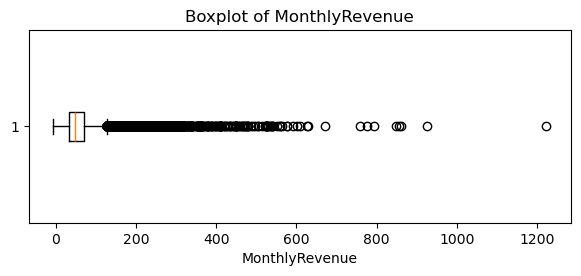

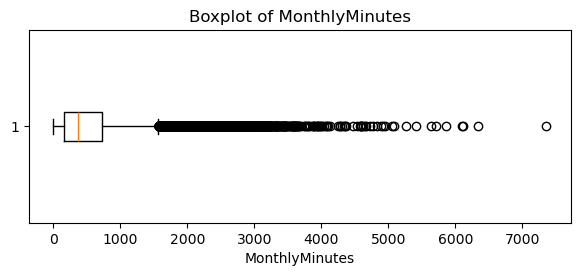

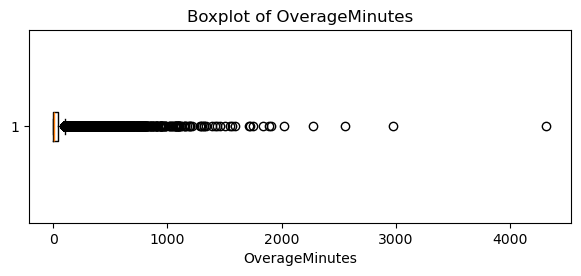

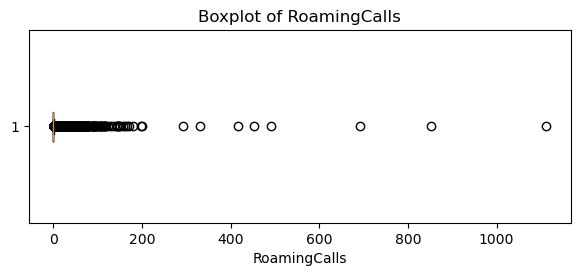

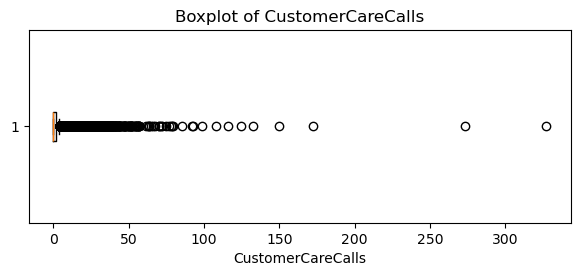

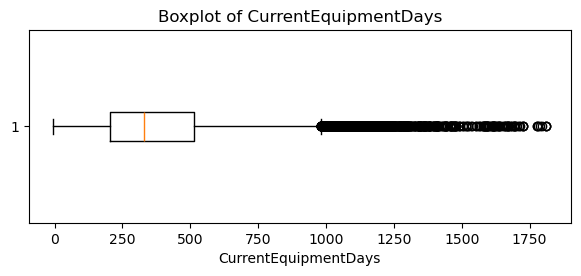

In [53]:
# Selected boxplots for variables with potentially important extreme values
outlier_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays"
]

for col in outlier_features:
    plt.figure(figsize=(7, 2.5))
    plt.boxplot(
        train_raw[col].dropna(),
        vert=False
    )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

**Interpretation**

The IQR analysis flags numerous observations in several usage-related variables. This is not sufficient evidence that those records are erroneous. Telecommunications usage can naturally include customers with activity levels far above the typical customer.

Accordingly, the audit records the existence of statistically unusual observations but does not remove, cap or transform them. Any later treatment must be justified using feature meaning and modelling evidence.

### 2.11 Target Distribution and Class Imbalance

The target distribution is inspected to determine whether the two churn classes are represented equally.

,Count,Percentage
Churn,,
No,36336,71.18
Yes,14711,28.82


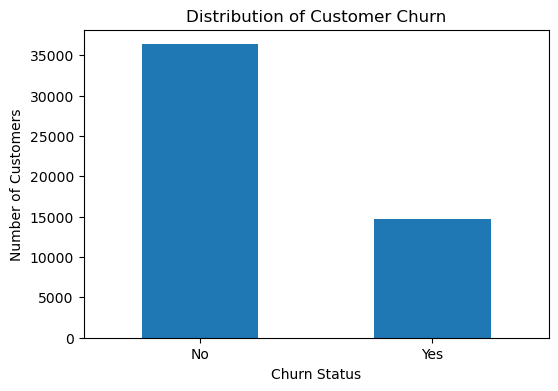

In [54]:
# Target distribution
target_counts = train_raw["Churn"].value_counts()
target_percentages = (
    train_raw["Churn"].value_counts(normalize=True) * 100
).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

# Visualise target distribution
plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

**Interpretation**

The labelled dataset contains **36,336 non-churn customers (approximately 71.18%)** and **14,711 churn customers (approximately 28.82%)**. The target therefore exhibits moderate class imbalance.

### 2.12 Holdout Target Integrity

The target column in the separate holdout file is checked to confirm whether true churn outcomes are available.

In [55]:
print(
    "Missing Churn labels in holdout:",
    holdout_raw["Churn"].isna().sum()
)

print(
    "Total holdout observations:",
    len(holdout_raw)
)

Missing Churn labels in holdout: 20000
Total holdout observations: 20000


**Interpretation**

All 20,000 `Churn` values in the provided holdout dataset are missing. Therefore, the holdout dataset cannot be used to calculate evaluation measures such as Accuracy, Precision, Recall, F1-score or ROC-AUC. It is retained as an unlabelled dataset for possible final inference after the modelling and evaluation workflow is completed.

### 2.13 Data Audit Summary

| Audit Area | Main Finding |
|---|---|
| Dataset size | 51,047 labelled observations and 58 variables |
| Holdout data | 20,000 observations with no observed `Churn` labels |
| Feature types | Mixture of numerical, binary categorical, nominal and ordered categorical information |
| Target | Binary `Churn` (`Yes` / `No`) |
| Exact duplicates | No complete duplicate rows identified |
| Identifier integrity | `CustomerID` is unique for every labelled observation |
| Actual missing values | Multiple variables contain null values |
| Explicit unknown values | Present in `Homeownership`, `HandsetPrice` and `MaritalStatus` |
| Categorical cardinality | `ServiceArea` contains hundreds of distinct categories |
| Representation issue | `HandsetPrice` contains price-like values together with `Unknown`, producing an object data type |
| Numerical distributions | Several usage-related variables are skewed and contain long tails |
| Suspicious values | Negative/context-dependent values occur in selected numerical fields and require interpretation |
| Internal consistency | Selected logical relationship checks show no violations |
| Potential outliers | IQR analysis flags numerous observations, especially among usage-related variables |
| Target balance | Approximately 71.18% non-churn and 28.82% churn |
